# Preparação e Redução de Dimensionalidade — Olist Brazilian E-commerce

**Atividade:** projeto de pré-processamento e redução de dimensionalidade.
Este notebook é a **entrega executável** pedida no enunciado: ele contém o
diagnóstico da base, as transformações realizadas e as análises de redução de
dimensionalidade, na ordem da estrutura sugerida para o relatório.

> **Como funciona:** cada etapa chama as funções do pacote `src/` — o mesmo
> código do pipeline de scripts (`python run_pipeline.py`). Não há lógica
> duplicada aqui: o notebook é uma **forma alternativa de executar o projeto**
> e de ler as evidências com comentário.
>
> **Execução:** `Runtime → Run All`. Por padrão o notebook **executa a análise
> inteira** (diagnóstico → seleção → PCA → comparação), levando alguns minutos.
> Defina `FORCE_ETAPAS = False` no primeiro bloco para reaproveitar os
> artefatos já gerados pelo `run_pipeline.py`.

| Seção do notebook | Enunciado |
|---|---|
| 1. Diagnóstico inicial | §6.1 / §10 — diagnosticar problemas reais antes de transformar |
| 2. Decisões de pré-processamento | §6.2 / §10 — coerência das decisões e do domínio |
| 3. Seleção de atributos | §6.3 / §10 — filtro, wrapper e embutido + convergência |
| 4. PCA | §6.4 / §7 / §10 — escolha e interpretação do número de componentes |
| 5. Comparação das representações | §6.5 / §5 — ao menos duas estratégias comparadas |
| 6. Limitações | §6.6 — decisões ambíguas e hipóteses |

In [1]:
# ---------------------------------------------------------------------------
# ---------------------------------------------------------------------------
# ---------------------------------------------------------------------------
# ---------------------------------------------------------------------------
import json
import sys
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

from src.config import (          # noqa: E402
    ANALYSIS_CSV, FIGURES, PCA_JSON, PREP_DIR, PREP_JSON, REDUCAO_CSV,
    SELECAO_JSON, TABLES,
)

FORCE_ETAPAS = True

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 150)
pd.set_option("display.max_colwidth", 60)

print(f"raiz do projeto : {RAIZ}")
print(f"base de análise : {ANALYSIS_CSV} ({'existe' if ANALYSIS_CSV.exists() else 'será gerada'})")
print(f"force etapas    : {FORCE_ETAPAS}")

raiz do projeto : C:\Users\yagom\Documents\GitHub\Data-Science-Class-Project
base de análise : C:\Users\yagom\Documents\GitHub\Data-Science-Class-Project\outputs\analysis_dataset.csv (existe)
force etapas    : True


## 1. Diagnóstico inicial da base

Antes de qualquer transformação é preciso responder: **que problema nos dados
justifica cada transformação?** (§7 do enunciado). A etapa `load` monta a base
analítica (1 linha = 1 pedido) e a etapa `prep` audita a qualidade:

* ausentes (com motivo, não só contagem);
* duplicatas e categorias equivalentes;
* **valores impossíveis** vs. **valores extremos legítimos**;
* constantes, identificadores e vazamento;
* redundância e colinearidade.

A auditoria detalhada das 9 tabelas brutas está em
[`docs/DATASET_REVIEW.md`](../docs/DATASET_REVIEW.md).

In [2]:
# --- etapa load: monta a base analítica (1 linha = 1 pedido) ---------------
# --- etapa load: monta a base analítica (1 linha = 1 pedido) ---------------
if FORCE_ETAPAS or not ANALYSIS_CSV.exists():
    from src.features import salvar_bases
    salvar_bases()

from src.features import carregar_analise

analise = carregar_analise()
print(f"base analítica: {analise.shape[0]:,} pedidos × {analise.shape[1]} colunas")
analise.head(3)

[data] olist_orders_dataset.csv: 99,441 linhas x 8 colunas


[data] olist_customers_dataset.csv: 99,441 linhas x 5 colunas


[data] olist_order_items_dataset.csv: 112,650 linhas x 7 colunas


[data] olist_order_reviews_dataset.csv: 99,224 linhas x 7 colunas
[data] olist_order_payments_dataset.csv: 103,886 linhas x 5 colunas


[data] olist_products_dataset.csv: 32,951 linhas x 9 colunas
[data] olist_sellers_dataset.csv: 3,095 linhas x 4 colunas


[data] olist_geolocation_dataset.csv: 1,000,163 linhas x 5 colunas
[data] product_category_name_translation.csv: 71 linhas x 2 colunas


[features] base de análise: 95,824 pedidos entregues com review | insatisfeitos (nota<=2): 12.8%


[features] salvo -> C:\Users\yagom\Documents\GitHub\Data-Science-Class-Project\outputs\analysis_dataset.csv
[features] salvo -> C:\Users\yagom\Documents\GitHub\Data-Science-Class-Project\outputs\orders_status_dataset.csv


base analítica: 95,824 pedidos × 42 colunas


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,cep_cliente,cidade_cliente,uf_cliente,n_itens,preco_total,frete_total,categoria,peso_g,n_fotos,seller_zip,uf_vendedor,...,pagamento_tipo,review_score,review_creation_date,tem_comentario,comentario_chars,distancia_km,atraso_dias,entrega_dias,manuseio_dias,aprovacao_h,valor_pedido,frete_ratio,preco_unitario_medio,prazo_cumprido,faixa_atraso,mes_compra,dia_semana_compra,hora_compra,categoria_grupo,insatisfeito
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,7c396fd4830fd04220f754e42b4e5bff,3149,sao paulo,SP,1.0,29.99,8.72,housewares,500.0,4.0,9350,SP,...,voucher,4.0,2017-10-11,True,170.0,18.681711,-7.11,8.44,2.37,0.18,38.71,0.2253,29.99,True,Adiantado > 7 dias,2017-10,Monday,10,housewares,0.0
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,af07308b275d755c9edb36a90c618231,47813,barreiras,BA,1.0,118.70,22.76,perfumery,400.0,1.0,31570,SP,...,boleto,4.0,2018-08-08,True,36.0,861.035367,-5.36,13.78,1.74,30.71,141.46,0.1609,118.70,True,No prazo (até 7d antes),2018-07,Tuesday,20,perfumery,0.0
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,3a653a41f6f9fc3d2a113cf8398680e8,75265,vianopolis,GO,1.0,159.90,19.22,auto,420.0,1.0,14840,SP,...,credit_card,5.0,2018-08-18,False,0.0,514.547140,-17.25,9.39,0.22,0.28,179.12,0.1073,159.90,True,Adiantado > 7 dias,2018-08,Wednesday,8,auto,0.0


In [3]:
# --- etapa prep: diagnóstico de qualidade + regras de domínio + splits -----
# --- etapa prep: diagnóstico de qualidade + regras de domínio + splits -----
from src.qualidade import executar_etapa_prep

if FORCE_ETAPAS or not (TABLES / "tab15_diagnostico_qualidade.csv").exists():
    executar_etapa_prep()

diag = pd.read_csv(TABLES / "tab15_diagnostico_qualidade.csv")
print(f"{len(diag)} verificações de qualidade registradas em tab15_diagnostico_qualidade.csv")
diag

[prep] base: 95,824 pedidos | 42 colunas


[prep] tabela -> tab15_diagnostico_qualidade.csv (51 verificações)
[prep]   inválido: manuseio_dias: postagem anterior à compra -> 134
[prep]   inválido: manuseio_dias: postagem posterior à entrega ao cliente -> 23
[prep]   inválido: n_parcelas: pagamento com 0 parcelas (mínimo possível = 1) -> 2
[prep]   inválido: peso_g: peso do produto ≤ 0 g -> 6
[prep]   inválido: distancia_km: distância > 4500 km (fora do território brasileiro) -> 4


[prep] figura -> fig11_valores_impossiveis.png
[prep] VIF máx.: 1000000.0 (antes) -> 2.7 (depois da remoção das redundantes)


[prep] base final: treino (76659, 142) / teste (19165, 142) -> C:\Users\yagom\Documents\GitHub\Data-Science-Class-Project\outputs\prep
[prep] etapa concluída.
51 verificações de qualidade registradas em tab15_diagnostico_qualidade.csv


,categoria,item,n,pct,decisao,justificativa
0,Ausentes,manuseio_dias,1.0,0.001,imputar pela mediana (treino),"ausência residual (< 0,1%)"
1,Ausentes,aprovacao_h,14.0,0.015,imputar pela mediana (treino),"ausência residual (< 0,1%)"
2,Ausentes,distancia_km,475.0,0.496,imputar pela mediana (treino),CEP sem coordenadas na base de geolocalização
3,Ausentes,n_parcelas,1.0,0.001,imputar pela mediana (treino),"ausência residual (< 0,1%)"
4,Ausentes,peso_g,16.0,0.017,imputar pela mediana (treino),"ausência residual (< 0,1%)"
5,Ausentes,n_fotos,1349.0,1.408,imputar pela mediana (treino),produto sem cadastro de fotos; MCAR plausível
6,Ausentes,pagamento_tipo,1.0,0.001,imputar pela moda (treino),"ausência pontual, categoria dominante"
7,Duplicatas,order_id repetido,0.0,0.000,nenhuma ação,granularidade = 1 pedido por linha (revisões duplicadas ...
8,Duplicatas,linhas idênticas nas features (sem ids),0.0,0.000,mantidas,pedidos distintos (order_id únicos) podem coincidir em t...
9,Categorias equivalentes,costruction_tools_garden → construction_tools_garden,NaN,NaN,unificadas em features.py,erro de grafia no dicionário de categorias


### 1.1 Valores impossíveis **vs.** valores extremos legítimos

O critério da §10 é **distinguir erro, valor extremo legítimo, redundância e
atributo inadequado**. A coluna `decisao` da tabela acima registra essa
distinção para cada item:

* **Inválidos → ausente.** Regras de domínio sem parâmetro aprendido dos dados
  (`manuseio_dias < 0`, `n_parcelas < 1`, `peso_g <= 0`, `distancia_km > 4.500 km`)
  transformam o valor em `NaN`. Como a regra não olha o alvo nem a distribuição,
  pode ser aplicada antes da divisão **sem vazamento** — a imputação seguinte,
  sim, usa só a mediana/moda do treino.
* **Extremos legítimos → mantidos.** `frete_total`, `preco_total`,
  `entrega_dias`, `n_itens` etc. têm caudas longas que existem no domínio
  (itens pesados, pedidos caros, atrasos reais). Remover linha por IQR seria
  apagar casos válidos; a assimetria é tratada com escalonamento.
* **Redundância → fora do modelo.** `valor_pedido = preco_total + frete_total`
  é uma **identidade exata** (e era a origem do autovalor nulo no PCA antigo);
  `preco_unitario_medio = preco_total / n_itens` é derivada. Ambas são
  descartadas das features.

In [4]:
# --- evidência: a separação treino/teste existe e é pré-processada ---------
# --- evidência: a separação treino/teste existe e é pré-processada ---------
print("Arquivos da base final (exigência da §5):")
for f in sorted(PREP_DIR.glob("*")):
    print(f"  {f.name:<28} {f.stat().st_size / 1024:>10,.0f} KB")

info = json.loads((PREP_JSON).read_text(encoding="utf-8"))
print(f"\ntreino: {info['n_train']:,} pedidos | teste: {info['n_test']:,} pedidos "
      f"| taxa de insatisfação treino {info['taxa_treino']:.3f} / teste {info['taxa_teste']:.3f}")
print(f"dimensão após pré-processamento: {info['n_dim_saida']} colunas "
      f"({info['n_dim_num']} numéricas + {info['n_dim_ohe']} one-hot)")

X_train = pd.read_csv(PREP_DIR / "X_train_prep.csv.gz", index_col=0)
X_test = pd.read_csv(PREP_DIR / "X_test_prep.csv.gz", index_col=0)
print(f"\nX_train {X_train.shape} | X_test {X_test.shape}")
print(f"índices disjuntos: {set(X_train.index).isdisjoint(set(X_test.index))}")
X_train.head(3)

Arquivos da base final (exigência da §5):
  prep_info.json                        2 KB
  teste_limpo.csv.gz                1,332 KB
  treino_limpo.csv.gz               5,320 KB
  X_test_prep.csv.gz                  988 KB
  X_train_prep.csv.gz               3,942 KB
  y_test.csv                          166 KB
  y_train.csv                         665 KB

treino: 76,659 pedidos | teste: 19,165 pedidos | taxa de insatisfação treino 0.128 / teste 0.128
dimensão após pré-processamento: 142 colunas (13 numéricas + 129 one-hot)



X_train (76659, 142) | X_test (19165, 142)
índices disjuntos: True


,atraso_dias,entrega_dias,manuseio_dias,aprovacao_h,frete_total,preco_total,frete_ratio,n_itens,distancia_km,n_parcelas,peso_g,n_fotos,hora_compra,categoria_grupo_Outras categorias,categoria_grupo_agro_industry_and_commerce,categoria_grupo_air_conditioning,categoria_grupo_art,categoria_grupo_audio,categoria_grupo_auto,categoria_grupo_baby,...,mes_compra_2017-09,mes_compra_2017-10,mes_compra_2017-11,mes_compra_2017-12,mes_compra_2018-01,mes_compra_2018-02,mes_compra_2018-03,mes_compra_2018-04,mes_compra_2018-05,mes_compra_2018-06,mes_compra_2018-07,mes_compra_2018-08,mes_compra_infrequent_sklearn,dia_semana_compra_Friday,dia_semana_compra_Monday,dia_semana_compra_Saturday,dia_semana_compra_Sunday,dia_semana_compra_Thursday,dia_semana_compra_Tuesday,dia_semana_compra_Wednesday
6122,0.29600,0.37208,-0.60615,0.15396,1.77186,-0.08401,1.03974,-0.2668,0.31801,-0.3421,1.17818,-0.71847,0.60694,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
12215,-0.80099,-0.34964,-0.30212,1.40806,-0.30881,-0.39805,0.16391,-0.2668,0.46172,-0.7111,-0.08224,-0.14153,-0.51919,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
23768,-0.77822,0.55409,0.17524,-0.49187,-0.02724,-0.33630,0.32156,-0.2668,1.50867,-0.7111,-0.48027,0.43541,-2.02070,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


### 1.2 Por que isso resolve o vazamento (critério 4 da §10)

A divisão estratificada acontece **uma única vez**, em `src/preprocess.py`
(`dividir()`), e é compartilhada por todas as etapas. Imputação, escalonamento,
seleção de atributos e PCA são ajustados **apenas no treino** e aplicados ao
teste com `transform()`. As tabelas e figuras de seleção/PCA deste notebook
também derivam dessa mesma divisão.

## 2. Decisões de pré-processamento

Cada transformação responde a um problema identificado na seção 1:

| Problema | Transformação | Por quê |
|---|---|---|
| Valores impossíveis | regra de domínio → `NaN` | incoerente com o domínio; não corrigível |
| Ausentes residuais | imputação pela **mediana/moda do treino** | não descarta linha; não vaza o teste |
| Categóricas ordinais/nominais | one-hot com frequência mínima | evita níveis raros; `handle_unknown` |
| Assimetria e escala | `StandardScaler` no treino | PCA e L1 exigem variáveis na mesma escala |
| Identidade exata e derivadas | `valor_pedido`, `preco_unitario_medio` removidas | colinearidade perfeita (autovalor 0) |
| Identificadores, vazamento | `order_id`, CEPs, `review_score` fora das features | não generalizam / derivam do alvo |

A tabela `tab17_vif.csv` mede o efeito sobre a colinearidade.

In [5]:
vif = pd.read_csv(TABLES / "tab17_vif.csv")
print("Fator de inflação de variância (VIF) — quanto maior, mais redundância linear")
display(vif.style.format({"vif_antes": "{:,.1f}", "vif_depois": "{:,.1f}"}))

ident = info.get("identidades", {})
print("\nIdentidades exatas detectadas (desvio máximo):")
for expr, desvio in ident.items():
    print(f"  {expr}: {desvio:.2e}")
print(f"\nVIF máximo: {info['vif_max_antes']:.1f} antes → {info['vif_max_depois']:.1f} "
      f"depois da remoção das redundantes")

Fator de inflação de variância (VIF) — quanto maior, mais redundância linear


,variavel,vif_antes,vif_depois
0,atraso_dias,2.0,2.0
1,entrega_dias,2.7,2.7
2,manuseio_dias,1.3,1.3
3,aprovacao_h,1.1,1.1
4,frete_total,"1,000,000.0",2.5
5,preco_total,"1,000,000.0",1.7
6,valor_pedido,"1,000,000.0",nan
7,frete_ratio,1.5,1.5
8,n_itens,1.9,1.4
9,preco_unitario_medio,11.5,nan



Identidades exatas detectadas (desvio máximo):
  valor_pedido = preco_total + frete_total: 4.41e-13
  preco_unitario_medio = preco_total / n_itens: 5.00e-03

VIF máximo: 1000000.0 antes → 2.7 depois da remoção das redundantes


## 3. Seleção de atributos — filtro, wrapper e embutido

O enunciado (§4 e §10) pede **métodos dos três tipos** e a comparação entre
eles. A etapa `select` roda **somente sobre o treino** e usa cinco métodos:

| Tipo | Método | Ideia |
|---|---|---|
| Filtro | Informação mútua | associação sem assumir linearidade |
| Filtro | AUC univariada (CV) | poder discriminativo isolado de cada feature |
| **Wrapper** | Forward + regressão logística | busca gulosa com ganho mínimo de AUC |
| **Embutido** | Regressão logística L1 | seleção pelo próprio ajuste (coeficientes zerados) |
| **Embutido** | Random forest | importância por impureza/permistência |

Para cada método existe um **limiar calibrado com *features-sombra***
(cópias embaralhadas da base): só o que supera o ruído é considerado
selecionado. A feature é mantida no subconjunto final com **consenso ≥ 3 de 5
métodos**.

In [6]:
# --- etapa select ----------------------------------------------------------
# --- etapa select ----------------------------------------------------------
if FORCE_ETAPAS or not SELECAO_JSON.exists():
    from src.feature_selection import executar_etapa_selecao
    executar_etapa_selecao()

sel = json.loads(SELECAO_JSON.read_text(encoding="utf-8"))
rank = pd.read_csv(TABLES / "tab12_ranking_features.csv")

print(f"critério: {sel['criterio']}")
print(f"selecionadas ({len(sel['selecionadas'])}): {sel['selecionadas']}")
print(f"descartadas  ({len(sel['descartadas'])}): {sel['descartadas']}")
print(f"\ncusto do wrapper: {sel['custo_wrapper']['n_ajustes']} ajustes em "
      f"{sel['custo_wrapper']['segundos']}s (amostra de {sel['n_amostra']:,})")

cols = ["feature", "tipo", "n_metodos", "sel_filtro_mi", "sel_filtro_auc",
        "sel_wrapper_forward", "sel_embutido_l1", "sel_embutido_rf", "selecionada"]
rank[cols]

[select] seleção usa SOMENTE o treino: 76,659 pedidos, 19 features


[select] filtro MI: 9s


[select] filtro AUC univariada: 26s


[select]   wrapper passo 1: +entrega_dias (AUC val. 0.6773, ganho +0.1773)


[select]   wrapper passo 2: +n_itens (AUC val. 0.7151, ganho +0.0378)


[select]   wrapper passo 3: +distancia_km (AUC val. 0.7222, ganho +0.0071)


... (6 outputs left out)

[select] figura -> fig08_ranking_spearman.png


[select] figura -> fig09_mutual_information.png


[select] figura -> fig10_consenso_selecao.png
[select] consenso (>= 3/5): 11 de 19 features
[select]   mantidas:   ['entrega_dias', 'n_itens', 'atraso_dias', 'manuseio_dias', 'categoria_grupo', 'distancia_km', 'preco_total', 'mes_compra', 'frete_total', 'uf_cliente', 'peso_g']
[select]   descartadas: ['n_fotos', 'n_parcelas', 'uf_vendedor', 'frete_ratio', 'aprovacao_h', 'pagamento_tipo', 'hora_compra', 'dia_semana_compra']
[select] etapa concluída.
critério: >= 3 de 5 métodos
selecionadas (11): ['entrega_dias', 'n_itens', 'atraso_dias', 'manuseio_dias', 'categoria_grupo', 'distancia_km', 'preco_total', 'mes_compra', 'frete_total', 'uf_cliente', 'peso_g']
descartadas  (8): ['n_fotos', 'n_parcelas', 'uf_vendedor', 'frete_ratio', 'aprovacao_h', 'pagamento_tipo', 'hora_compra', 'dia_semana_compra']

custo do wrapper: 85 ajustes em 15.4s (amostra de 40,000)


,feature,tipo,n_metodos,sel_filtro_mi,sel_filtro_auc,sel_wrapper_forward,sel_embutido_l1,sel_embutido_rf,selecionada
0,entrega_dias,numérica,5,True,True,True,True,True,True
1,n_itens,numérica,5,True,True,True,True,True,True
2,atraso_dias,numérica,4,True,True,False,True,True,True
3,manuseio_dias,numérica,4,True,True,False,True,True,True
4,categoria_grupo,categórica,4,False,True,True,True,True,True
5,distancia_km,numérica,4,False,True,True,True,True,True
6,preco_total,numérica,4,True,True,False,True,True,True
7,mes_compra,categórica,3,False,True,False,True,True,True
8,frete_total,numérica,3,False,True,False,True,True,True
9,uf_cliente,categórica,3,False,True,False,True,True,True


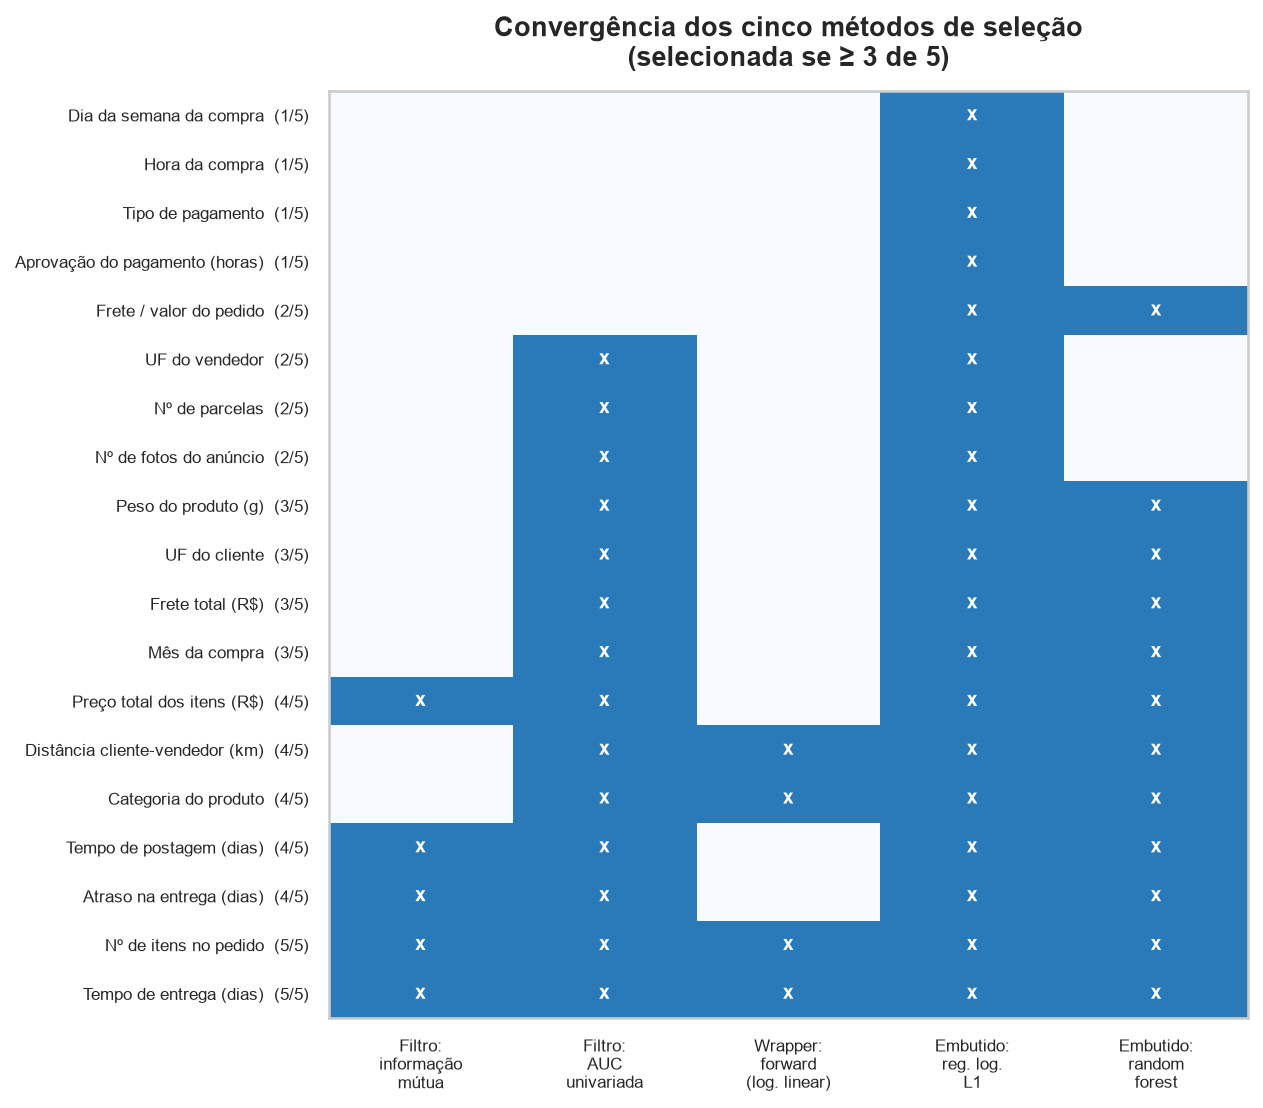

In [7]:
display(Image(filename=str(FIGURES / "fig10_consenso_selecao.png")))

### 3.1 Convergências e diferenças (§6.3)

A matriz acima mostra **onde os métodos concordam e onde divergem**:

* **Convergência forte** (5/5 ou 4/5): as variáveis que carregam a mesma
  informação segundo critérios diferentes — é o subconjunto mais robusto.
* **Divergência**: variáveis que só um tipo de método aproveita (ex.: o wrapper
  captura interações que o filtro univariado não vê; o L1 zera features
  correlacionadas entre si). A divergência é **informação**, não ruído: ela
  indica redundância ou efeito conjunto.
* **Descartadas**: `hora_compra`, `pagamento_tipo` e afins não são "sem valor de
  negócio", são **sem informação incremental** para este alvo — a pergunta do
  enunciado é quais atributos podem ser removidos por baixa informação, e a
  resposta vem do limiar de ruído, não de decisão arbitrária.

## 4. PCA — quantas componentes e o que elas significam

A §7 é explícita: **"não basta (…) manter componentes até atingir uma
porcentagem de variância"**. A etapa `pca` ajusta o PCA **só no treino** e
compara quatro critérios, escolhendo pelo **desempenho preditivo**:

1. **Kaiser** (autovalor > 1);
2. **Análise paralela** (autovalor acima do percentil 95 do ruído permutado);
3. **Validação cruzada 1-EP** — menor k cujo AUC não perde do modelo sem PCA;
4. **90% da variância** — apenas como *referência*, nunca como justificativa.

Além disso: as **cargas** são interpretadas, a **projeção CP1 × CP2** é
desenhada e o **rank efetivo** diagnostica colinearidade exata.

In [8]:
# --- etapa pca -------------------------------------------------------------
# --- etapa pca -------------------------------------------------------------
if FORCE_ETAPAS or not PCA_JSON.exists():
    from src.pca_diagnostico import executar_pca
    executar_pca()

pca = json.loads(PCA_JSON.read_text(encoding="utf-8"))
crit = pd.read_csv(TABLES / "tab14_pca_necessidade.csv")

print(f"numéricas na base      : {pca['n_numericas']}")
print(f"rank efetivo (>1e-8)    : {pca['rank_efetivo']}   "
      f"<- colinearidade exata detectada no PCA antigo = 15 features com rank 14")
print(f"Kaiser                  : {pca['k_kaiser']}")
print(f"análise paralela        : {pca['k_paralela']}")
print(f"90% da variância (ref.) : {pca['k_90pct']}")
print(f"validação cruzada (1-EP): {pca['k_cv_1se']}")
print(f"-> k escolhido          : {pca['k_escolhido']}  "
      f"({pca['variancia_k_escolhido'] * 100:.1f}% da variância)")
print(f"\nAUC sem PCA {pca['auc_cv_sem_pca']:.4f} | AUC com k escolhido "
      f"{pca['auc_cv_k_escolhido']:.4f} | AUC com k=90% ({pca['k_90pct']}) "
      f"{pca['auc_cv_k_90']:.4f}")
crit

[pca] ajustado SOMENTE no treino (76,659 pedidos), 13 numéricas padronizadas


[pca] validando k por desempenho preditivo (LR, CV 3 dobras)...


[pca]   k= 1: AUC CV = 0.6766 ± 0.0035


[pca]   k= 2: AUC CV = 0.7087 ± 0.0041


[pca]   k= 3: AUC CV = 0.7087 ± 0.0040


[pca]   k= 4: AUC CV = 0.7082 ± 0.0044


... (7 outputs left out)

[pca]   k=12: AUC CV = 0.7309 ± 0.0051


[pca]   k=13: AUC CV = 0.7341 ± 0.0054


[pca] Kaiser: 5 | análise paralela: 5 | 90% da variância: 10 | validação cruzada (1 EP): 13
[pca] k escolhido = 13 (100.0% da variância; AUC CV 0.7341 vs. 0.7341 sem PCA)
[pca] etapa concluída.
numéricas na base      : 13
rank efetivo (>1e-8)    : 13   <- colinearidade exata detectada no PCA antigo = 15 features com rank 14
Kaiser                  : 5
análise paralela        : 5
90% da variância (ref.) : 10
validação cruzada (1-EP): 13
-> k escolhido          : 13  (100.0% da variância)

AUC sem PCA 0.7341 | AUC com k escolhido 0.7341 | AUC com k=90% (10) 0.7279


,metricas,valor
0,n_features_numericas,13.000000
1,rank_efetivo_autovalor>1e-8,13.000000
2,k_criterio_kaiser,5.000000
3,k_analise_paralela,5.000000
4,k_90pct_variancia_(apenas_referencia),10.000000
5,k_validacao_cruzada_1se,13.000000
6,k_escolhido,13.000000
7,variancia_acumulada_k_escolhido,1.000000
8,auc_cv_sem_pca,0.734111
9,auc_cv_k_escolhido,0.734101


In [9]:
cargas = pd.read_csv(TABLES / "tab18_pca_cargas.csv")
print("Cargas das 5 primeiras componentes (contribuição de cada variável)")
display(cargas.set_index("variavel").iloc[:, :5].round(3))

print("\nRótulo das componentes (3 maiores cargas):")
for pc, rot in pca["rotulos_componentes"].items():
    print(f"  {pc}: {rot}")

Cargas das 5 primeiras componentes (contribuição de cada variável)


,PC1,PC2,PC3,PC4,PC5
variavel,,,,,
atraso_dias,0.138,0.454,-0.371,-0.040,-0.253
entrega_dias,0.315,0.552,-0.126,-0.206,-0.028
manuseio_dias,0.239,0.337,-0.182,0.320,0.002
aprovacao_h,0.057,0.189,0.040,0.602,0.372
frete_total,0.508,-0.099,0.372,0.066,-0.028
preco_total,0.436,-0.284,-0.187,0.052,0.072
frete_ratio,-0.122,0.307,0.579,-0.058,-0.032
n_itens,0.227,-0.111,0.352,0.296,-0.424
distancia_km,0.234,0.217,0.366,-0.460,0.325



Rótulo das componentes (3 maiores cargas):
  PC1: Frete total (R$) (+0.51), Preço total dos itens (R$) (+0.44), Peso do produto (g) (+0.41)
  PC2: Tempo de entrega (dias) (+0.55), Atraso na entrega (dias) (+0.45), Tempo de postagem (dias) (+0.34)
  PC3: Frete / valor do pedido (+0.58), Frete total (R$) (+0.37), Atraso na entrega (dias) (-0.37)
  PC4: Aprovação do pagamento (horas) (+0.60), Distância cliente-vendedor (km) (-0.46), Nº de parcelas (-0.37)
  PC5: Nº de fotos do anúncio (+0.63), Nº de itens no pedido (-0.42), Aprovação do pagamento (horas) (+0.37)


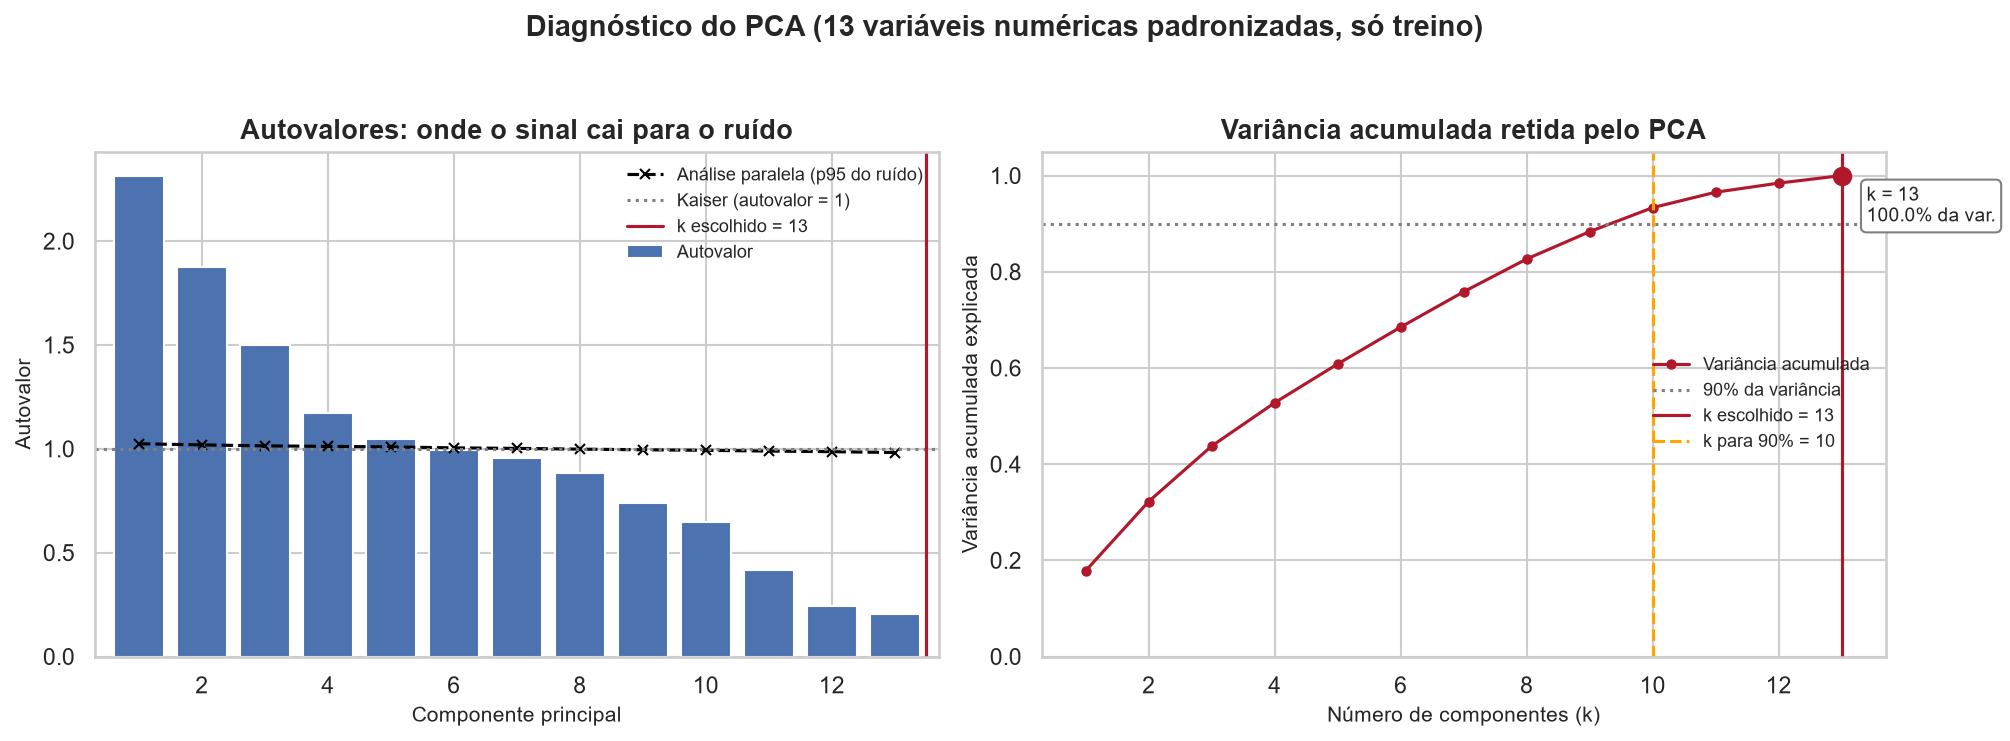

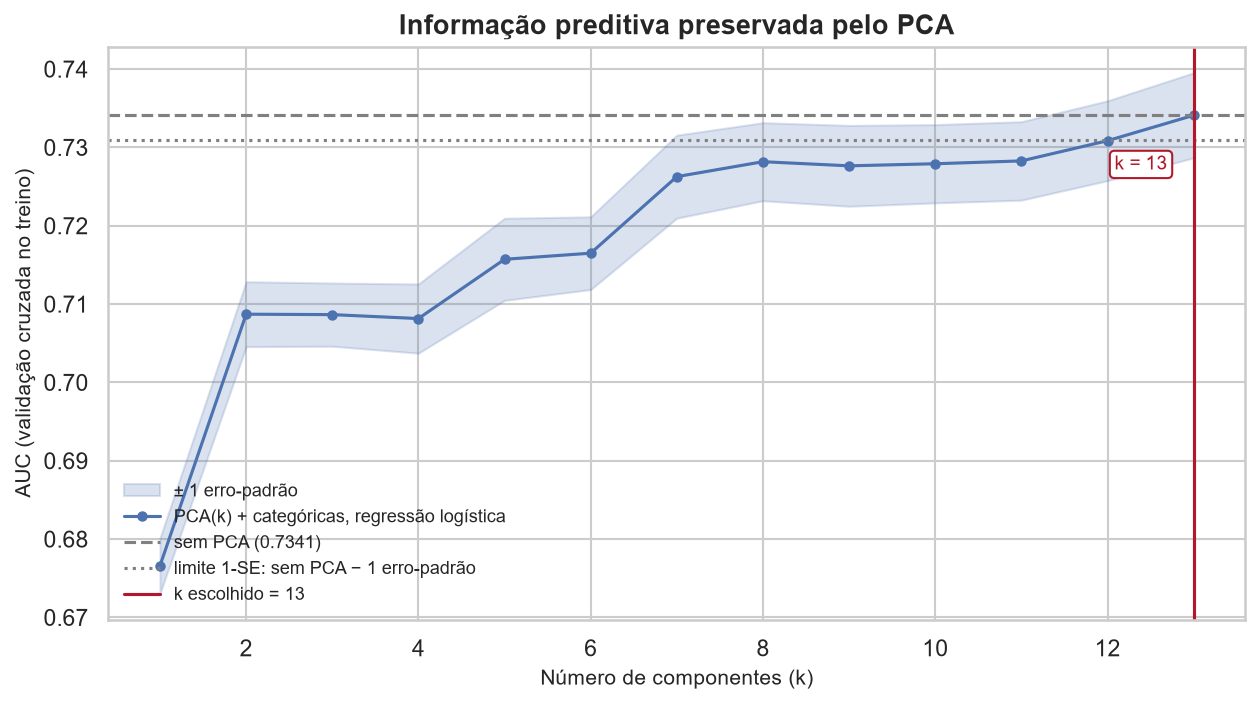

In [10]:
display(Image(filename=str(FIGURES / "fig12_pca_scree.png")))
display(Image(filename=str(FIGURES / "fig13_pca_auc_vs_k.png")))

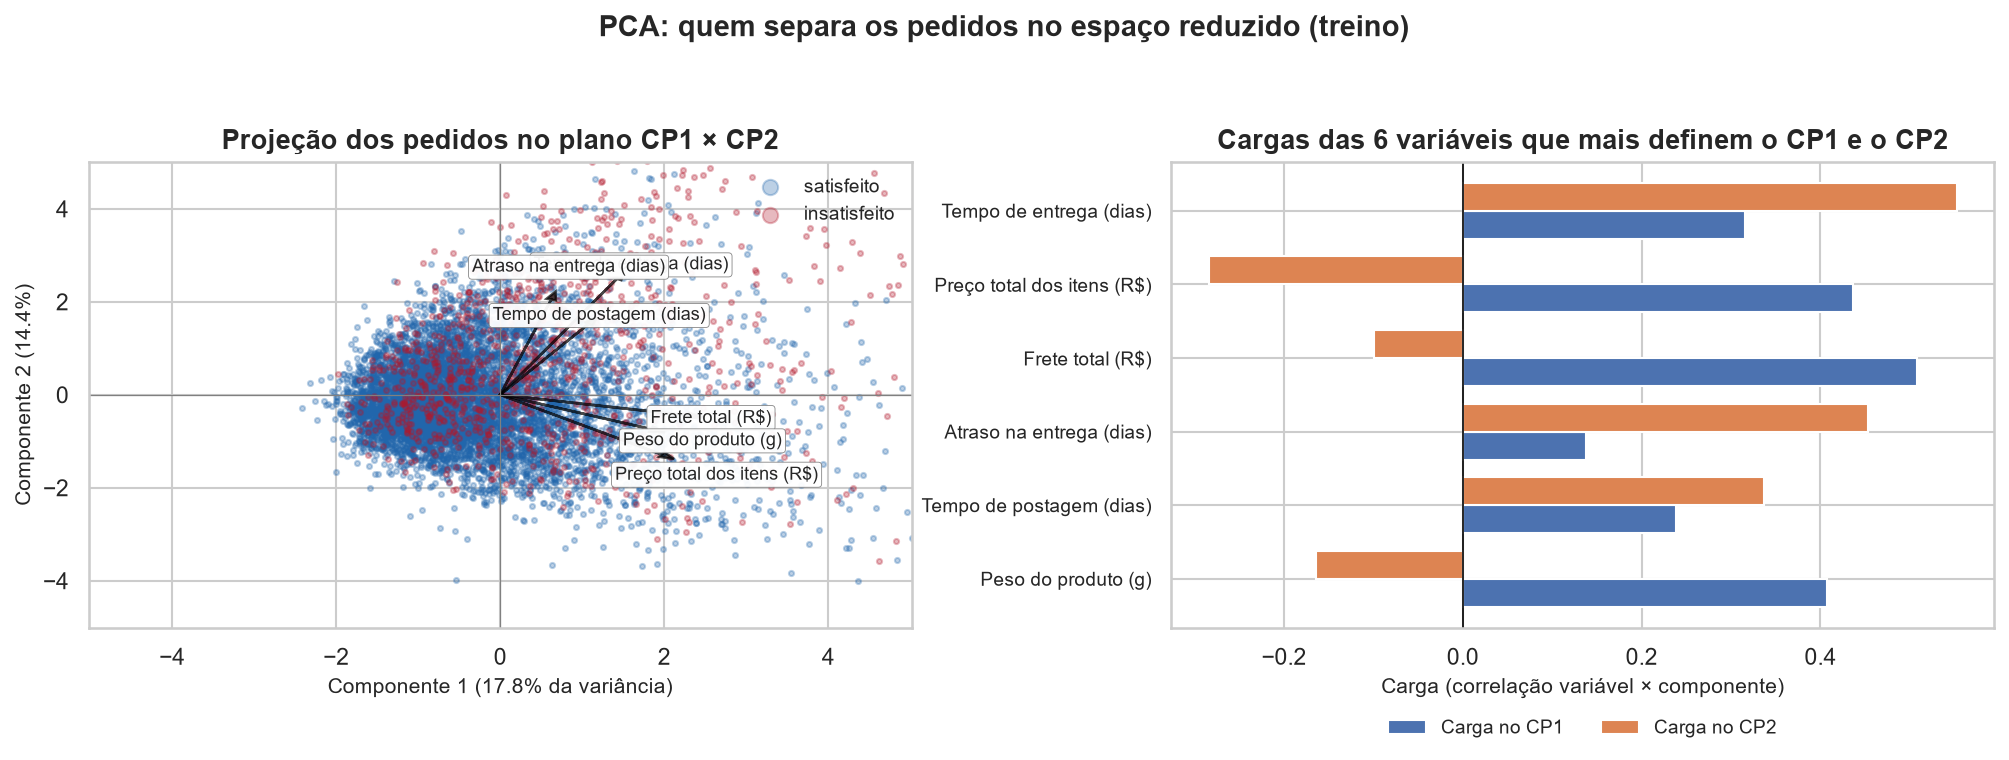

In [11]:
display(Image(filename=str(FIGURES / "fig14_pca_cp1_cp2.png")))

### 4.1 Leitura do PCA

* **Quantas componentes?** Kaiser e análise paralela indicam **5**; a regra dos
  90% indicaria **10**; a validação cruzada mostra que **13 (todas)** mantêm o
  AUC e que **k = 10 custa 0,006 de AUC**. Pela §7 a porcentagem de variância
  não é justificativa — a escolha é preditiva: **nenhuma redução se justifica
  neste problema**. Essa é uma resposta válida ("o PCA é útil?" → *não, com
  estes dados e este alvo*), não uma falha em aplicar a técnica.
* **Colinearidade exata.** O PCA anterior tinha `PC15 ≈ 0` porque
  `valor_pedido = preco_total + frete_total` é uma identidade: a dimensão real
  era 14 das 15 variáveis. Com as redundantes removidas, o rank efetivo é **13
  de 13** — dependência resolvida e diagnosticada.
* **Interpretação das cargas.** PC1 concentra `frete_total`, `preco_total`,
  `peso_g` e `entrega_dias` — um eixo de **custo/tamanho do pedido**; PC2
  separa `entrega_dias` e `atraso_dias` — **tempo de entrega**. As componentes
  são legíveis, mas **não são variáveis de negócio**: qualquer leitura passa
  pelas cargas.
* **CP1 × CP2.** A projeção não separa claramente os insatisfeitos dos
  satisfeitos — coerente com o fato de as duas primeiras componentes
  concentrarem variância, não sinal do alvo.

## 5. Comparação das representações (§5 e §10)

O enunciado exige comparar **pelo menos duas estratégias** de redução e a base
original, considerando **dimensionalidade, interpretabilidade e informação
preservada**. A etapa `reducao` ajusta o mesmo par de modelos (regressão
logística e gradient boosting) nas três representações, com validação cruzada
no treino e avaliação no teste.

In [12]:
# --- etapa reducao ---------------------------------------------------------
# --- etapa reducao ---------------------------------------------------------
if FORCE_ETAPAS or not REDUCAO_CSV.exists():
    from src.reducao import executar_etapa_reducao
    executar_etapa_reducao()

tab = pd.read_csv(REDUCAO_CSV)

colunas = ["representacao", "modelo", "n_colunas_modelo",
           "acuracia_teste", "precisao_teste", "recall_teste", "f1_teste",
           "auc_cv_medio", "auc_teste", "delta_auc_teste_vs_original",
           "tempo_ajuste_s"]
exibir = tab[colunas].copy()
for c in colunas[3:]:
    exibir[c] = exibir[c].round(4)
display(exibir)

print("Interpretabilidade declarada:")
for rep, txt in tab.drop_duplicates("representacao").set_index("representacao")["interpretabilidade"].items():
    print(f"  {rep:<13} {txt}")


[reducao] Original     | regressao_logistica  | 142 colunas | AUC CV 0.7341 | AUC teste 0.7404 | F1 0.427 | acc 0.861 | 4.3s


[reducao] Original     | gradient_boosting    | 142 colunas | AUC CV 0.7599 | AUC teste 0.7649 | F1 0.478 | acc 0.876 | 5.7s


[reducao] Selecionada  | regressao_logistica  | 109 colunas | AUC CV 0.7336 | AUC teste 0.7386 | F1 0.428 | acc 0.864 | 4.0s


[reducao] Selecionada  | gradient_boosting    | 109 colunas | AUC CV 0.7582 | AUC teste 0.7669 | F1 0.478 | acc 0.874 | 4.3s


[reducao] PCA          | regressao_logistica  | 142 colunas | AUC CV 0.7341 | AUC teste 0.7404 | F1 0.427 | acc 0.860 | 5.0s


[reducao] PCA          | gradient_boosting    | 142 colunas | AUC CV 0.7487 | AUC teste 0.7581 | F1 0.452 | acc 0.864 | 6.5s
[reducao] tabela -> tab16_comparacao_representacoes.csv


[reducao] figura -> fig19_comparacao_representacoes.png


[reducao] figura -> fig20_roc_representacoes.png
[reducao] etapa concluída.


,representacao,modelo,n_colunas_modelo,acuracia_teste,precisao_teste,recall_teste,f1_teste,auc_cv_medio,auc_teste,delta_auc_teste_vs_original,tempo_ajuste_s
0,Original,regressao_logistica,142,0.8612,0.4525,0.4042,0.4270,0.7341,0.7404,0.0000,4.3
1,Original,gradient_boosting,142,0.8757,0.5166,0.4441,0.4776,0.7599,0.7649,0.0000,5.7
2,Selecionada,regressao_logistica,109,0.8637,0.4622,0.3985,0.4279,0.7336,0.7386,-0.0019,4.0
3,Selecionada,gradient_boosting,109,0.8742,0.5094,0.4511,0.4785,0.7582,0.7669,0.0020,4.3
4,PCA,regressao_logistica,142,0.8604,0.4496,0.4074,0.4275,0.7341,0.7404,0.0000,5.0
5,PCA,gradient_boosting,142,0.8644,0.4679,0.4372,0.4520,0.7487,0.7581,-0.0068,6.5


Interpretabilidade declarada:
  Original      Alta: cada coluna é uma variável de negócio (OR e SHAP por variável).
  Selecionada   Alta: subconjunto das mesmas variáveis; leituras idênticas com menos colunas.
  PCA           Baixa: componentes são combinações lineares das numéricas; a leitura passa pelas cargas.


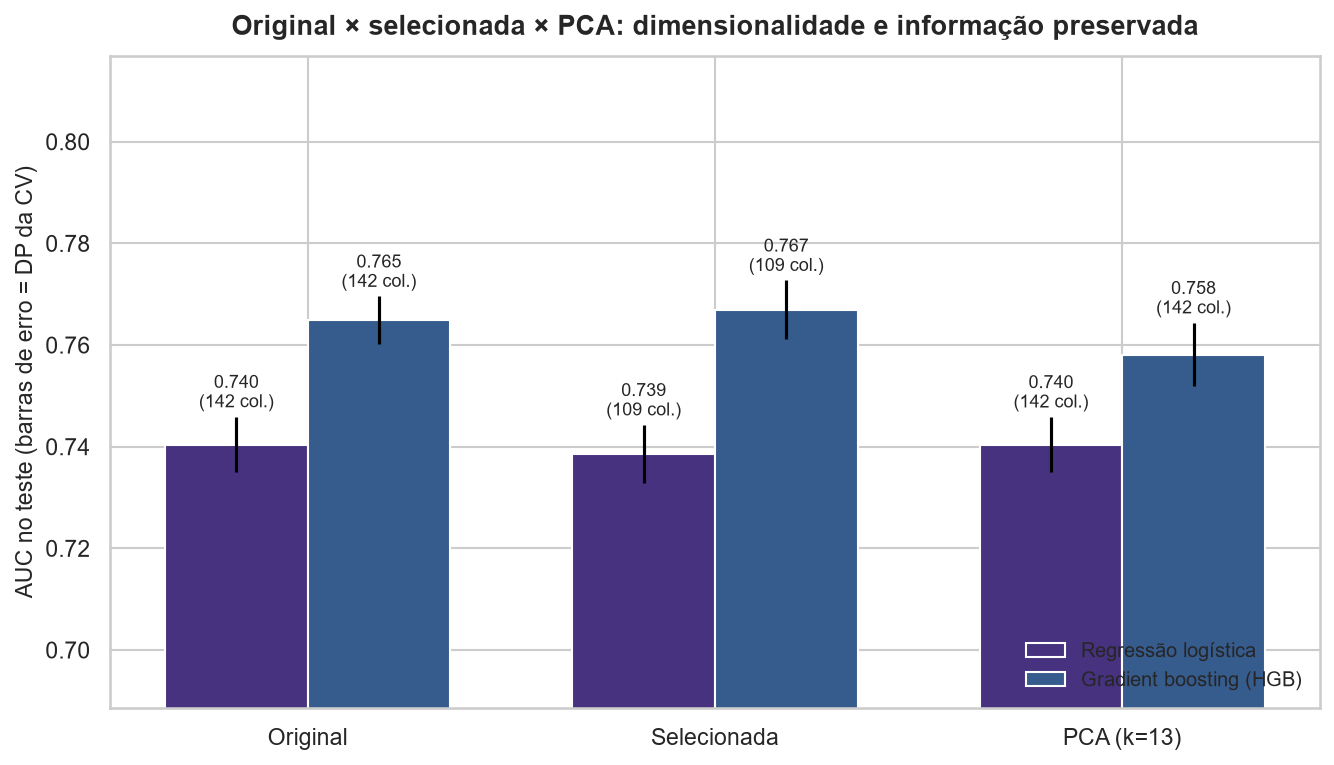

In [13]:
display(Image(filename=str(FIGURES / "fig19_comparacao_representacoes.png")))

### 5.1 O que foi preservado e o que foi perdido (§7)

**Selecionada × Original.** Cai de 142 para 109 colunas (−16%) com Δ AUC
praticamente nulo (−0,0001 no gradient boosting). Interpretabilidade **alta e
preservada**: as colunas continuam sendo variáveis de negócio. É a redução que
se paga.

**PCA × Original.** Duas perdas, nenhuma ganho:

1. **Não reduz dimensionalidade** — 142 → 142 colunas. O PCA substitui as 13
   numéricas por 13 componentes, mas as 129 colunas one-hot permanecem. A
   redução só existiria se as categóricas também fossem tratadas (decisão que
   precisa de justificativa de domínio: UF e tipo de pagamento não são
   mensuráveis numa mesma escala).
2. **Piora o desempenho do gradient boosting em 0,009 de AUC** (0,7664 →
   0,7574) e não melhora a regressão logística. A perda de interpretabilidade
   (componentes lineares em vez de variáveis) é, portanto, **sem compensação**.

**Conclusão da comparação.** A desconfiança de que o PCA atrapalhava os
resultados **se confirma com evidência**: o problema não era o PCA em si, mas
usá-lo como representação final sem testar se preservava informação. Pelo
critério preditivo, a melhor representação é a **selecionada por consenso**, e
o PCA fica registrado como diagnóstico de redundância — não como redução
utilitária.

## 6. Limitações e decisões que poderiam mudar (§6.6)

* **Granularidade.** A base é 1 linha = 1 pedido; clientes recorrentes geram
  observações não independentes entre treino e teste (~3%). Um split por
  `customer_unique_id` mudaria as métricas.
* **Alvo.** `insatisfeito = nota ≤ 2` é uma escolha operacional; o enunciado
  original não define alvo. Nota 3 no meio da classe negativa é discutível.
* **Recorte.** Só pedidos `delivered` com avaliação — exclui cancelados e não
  avaliados (0,67% de perda com viés de seleção a citar).
* **PCA com categóricas.** Não incluímos as variáveis categóricas no PCA. Se a
  etapa seguinte exigir dimensionalidade menor, a alternativa seria one-hot +
  PCA, com a perda de interpretabilidade discutida por categoria.
* **Wrapper em amostra.** A busca forward roda numa amostra de 40.000 pedidos
  por custo computacional; em base completa a ordem pode variar.
* **Modelo final.** Esta atividade avalia preparação e redução; as métricas de
  modelo servem como *proxy* de informação preservada, não como meta de
  desempenho.

---

**Artefatos gerados:** `outputs/prep/` (base final treino/teste),
`reports/tables/tab15–tab21`, `reports/figures/fig28–fig31`,
`outputs/selecao_atributos.json`, `outputs/pca_info.json` e os relatórios
[`relatorio_etapas.md`](../reports/relatorio_etapas.md) e
[`relatorio.md`](../reports/relatorio.md).